**Самостоятельная работа №1, Чеботарев Павел Александрович**

In [24]:
import torch
from torch import nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os
import torchvision.models as models
from tqdm import tqdm
import matplotlib.pyplot as plt

In [25]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [26]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("maysee/mushrooms-classification-common-genuss-images")
for root, dirs, files in os.walk(path):
  if len(files) == 0 and len(dirs) > 5:
    print(root)
    print(dirs)

Using Colab cache for faster access to the 'mushrooms-classification-common-genuss-images' dataset.
/kaggle/input/mushrooms-classification-common-genuss-images/Mushrooms
['Entoloma', 'Suillus', 'Hygrocybe', 'Agaricus', 'Amanita', 'Lactarius', 'Russula', 'Boletus', 'Cortinarius']
/kaggle/input/mushrooms-classification-common-genuss-images/mushrooms/Mushrooms
['Entoloma', 'Suillus', 'Hygrocybe', 'Agaricus', 'Amanita', 'Lactarius', 'Russula', 'Boletus', 'Cortinarius']


In [27]:
transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [28]:
data_path = "/kaggle/input/mushrooms-classification-common-genuss-images/Mushrooms"
full_dataset = datasets.ImageFolder(root=data_path, transform=transform)

In [29]:
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_data, test_data = torch.utils.data.random_split(full_dataset, [train_size, test_size])

batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)
print(len(full_dataset))
print(full_dataset.classes)

6714
['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


In [30]:
def train(net, train_loader, device, num_epochs, learning_rate):
    optimizer = optim.SGD(filter(lambda p: p.requires_grad, net.parameters()), lr=learning_rate, momentum=0.9)
    loss_function = torch.nn.CrossEntropyLoss()
    acc_history = []
    loss_history = []

    with tqdm(total=len(train_loader)*num_epochs, position=0, leave=True) as pbar:

        for epoch in range(num_epochs):
            running_loss = 0.0
            correct = 0
            total = 0

            for batch_num, (inputs, labels) in enumerate(train_loader):
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = net(inputs)
                loss = loss_function(outputs, labels)
                loss.backward()
                optimizer.step()

                running_loss += loss.item()

                _, predicted = outputs.max(1)
                batch_total = labels.size(0)
                batch_correct = predicted.eq(labels).sum().item()
                batch_acc = batch_correct/batch_total

                pbar.set_description("Epoch: %d, Batch: %2d, Loss: %.2f, Acc: %.2f" % (epoch, batch_num, running_loss / (batch_num + 1), batch_acc))
                pbar.update()

                total += batch_total
                correct += batch_correct
            acc = correct/total
            loss = running_loss/len(train_loader)
            acc_history.append(acc)
            loss_history.append(loss)
        pbar.close()
    return acc_history, loss_history

In [33]:
gt_model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
for param in gt_model.parameters():
  param.requires_grad = False
num_feat = gt_model.classifier[6].in_features
gt_model.classifier[6] = nn.Linear(num_feat, len(full_dataset.classes))
for param in gt_model.features[10].parameters():
  param.requires_grad = True
for param in gt_model.classifier[6].parameters():
  param.requires_grad = True

In [34]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [35]:
EPOCHS = 15
LR = 0.001
gt_model=gt_model.to(device)
hist_acc, hist_loss = train(gt_model, train_loader, device, EPOCHS, LR)

Epoch: 14, Batch: 167, Loss: 0.29, Acc: 0.93: 100%|██████████| 2520/2520 [13:48<00:00,  3.04it/s]


In [36]:
def print_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history)
    plt.title(title)
    plt.ylabel(title)
    plt.xlabel('Epoch')

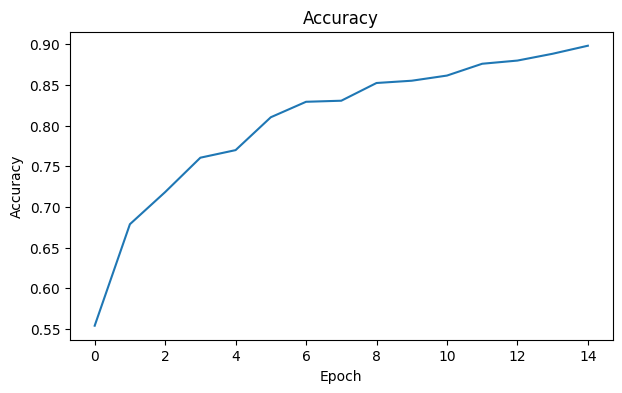

In [37]:
print_history(hist_acc, "Accuracy")

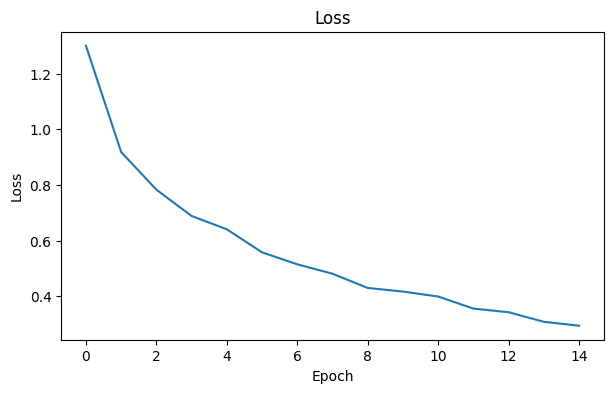

In [38]:
print_history(hist_loss, "Loss")

In [39]:
def evaluate_acc(net, test_loader, device):
  total = 0
  correct = 0
  net.eval()
  with torch.no_grad():
    for inputs, labels in test_loader:
      inputs = inputs.to(device)
      labels = labels.to(device)
      outputs = net(inputs)
      _, predicted = outputs.max(1)
      total += labels.size(0)
      correct += predicted.eq(labels).sum().item()
  return correct / total
test_acc = evaluate_acc(gt_model, test_loader, device)
print(test_acc)

0.7490692479523455
